# IALM Experiment No. 2: Comparison of Regression Techniques

## Aim
To implement and compare regression techniques on datasets with continuous targets and evaluate their predictive performance.

## Objectives
- Prepare and explore three regression datasets.
- Implement Simple Linear, Multiple Linear, Polynomial, Ridge, and Lasso Regression.
- Evaluate models using MAE, MSE, RMSE, and R².
- Visualize model performance and residuals.
- Summarize the best-performing approach for each dataset.

## Datasets
1. **Concrete:** predict compressive strength.
2. **Insurance:** predict insurance charges.
3. **Steel Industry:** predict electricity usage (`Usage_kWh`).

Only these three datasets are included. `online-retail.csv` and the classification-oriented CKD, heart-failure, and machine-failure datasets are not used in this regression experiment.

**Method note:** Steel observations are split chronologically. Concrete and Insurance use reproducible random train/test splits.

## 1. Setup and dataset paths

Place `concrete-data.csv`, `insurance.csv`, and `steel-industry.csv` inside a folder named `data/` beside this notebook. The notebook writes metric tables to `outputs/`.

In [1]:
# Uncomment if needed:
# %pip install pandas numpy matplotlib seaborn scikit-learn jupyter

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, TimeSeriesSplit, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_DIR.resolve()}. Create a 'data' folder beside this notebook "
        "and place the supplied CSV files in it."
    )

print("Notebook directory:", Path.cwd())
print("Dataset directory:", DATA_DIR.resolve())
print("CSV files found:", sorted(p.name for p in DATA_DIR.glob("*.csv")))

Notebook directory: /home/shriswarup/Documents/vjti/practicals/ialm/lab-two
Dataset directory: /home/shriswarup/Documents/vjti/practicals/ialm/lab-two/data
CSV files found: ['ckd.csv', 'concrete-data.csv', 'heart-failure.csv', 'insurance.csv', 'machine-failure.csv', 'steel-industry.csv']


## 2. Inspect the dataset files

This inventory confirms which CSV files the notebook expects. Other CSV files may remain in `data/`, but they are not loaded into the regression tasks.

In [2]:
def load_csv(filename, **kwargs):
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Required dataset not found: {path.resolve()}")
    return pd.read_csv(path, **kwargs)

available_files = sorted(DATA_DIR.glob("*.csv"))
inventory = []
for path in available_files:
    try:
        sample = pd.read_csv(path, nrows=3)
        inventory.append({
            "file": path.name,
            "columns_in_sample": len(sample.columns),
            "sample_rows_read": len(sample),
            "size_kb": round(path.stat().st_size / 1024, 1)
        })
    except Exception as exc:
        inventory.append({"file": path.name, "error": str(exc)})

display(pd.DataFrame(inventory))

,file,columns_in_sample,sample_rows_read,size_kb
0,ckd.csv,29,3,33.4
1,concrete-data.csv,9,3,57.9
2,heart-failure.csv,13,3,12.0
3,insurance.csv,7,3,54.3
4,machine-failure.csv,14,3,509.8
5,steel-industry.csv,11,3,2667.4


## 3. Clean and prepare the datasets

The target is the continuous value the model predicts. Concrete strength and insurance charges are continuous targets. Steel electricity usage (`Usage_kWh`) is also continuous.

For Steel Industry, invalid timestamps are removed, time fields are derived, and observations are sorted chronologically before splitting. `CO2(tCO2)` is excluded as a predictor because it may be derived from electricity usage and could leak information about the target.

In [3]:
# 3A. Concrete: predict compressive strength.
concrete_raw = load_csv("concrete-data.csv")
concrete = concrete_raw.copy()
concrete_target = "Concrete compressive strength(MPa, megapascals) "

# Convert all columns to numeric; nonnumeric metadata rows become missing values.
for col in concrete.columns:
    concrete[col] = pd.to_numeric(concrete[col], errors="coerce")
concrete = concrete.dropna(subset=[concrete_target]).copy()
concrete = concrete.loc[concrete[concrete_target] > 0].reset_index(drop=True)

concrete_task = {
    "name": "Concrete strength",
    "df": concrete,
    "target": concrete_target,
    "features": [c for c in concrete.columns if c != concrete_target],
    "time_ordered": False
}

# 3B. Insurance: predict charges from customer and policy-related features.
insurance = load_csv("insurance.csv").copy()
insurance["charges"] = pd.to_numeric(insurance["charges"], errors="coerce")
insurance = insurance.dropna(subset=["charges"]).reset_index(drop=True)
insurance_task = {
    "name": "Medical insurance charges",
    "df": insurance,
    "target": "charges",
    "features": [c for c in insurance.columns if c != "charges"],
    "time_ordered": False
}

# 3C. Steel Industry: predict electricity usage.
steel = load_csv("steel-industry.csv").copy()
steel["Usage_kWh"] = pd.to_numeric(steel["Usage_kWh"], errors="coerce")
steel["_timestamp"] = pd.to_datetime(steel["date"], errors="coerce", dayfirst=True)
invalid_timestamps = int(steel["_timestamp"].isna().sum())
invalid_targets = int(steel["Usage_kWh"].isna().sum())
steel = steel.dropna(subset=["_timestamp", "Usage_kWh"]).copy()
steel = steel.sort_values("_timestamp").reset_index(drop=True)

steel["hour"] = steel["_timestamp"].dt.hour
steel["month"] = steel["_timestamp"].dt.month
steel["day"] = steel["_timestamp"].dt.day
steel["dayofweek_num"] = steel["_timestamp"].dt.dayofweek

# Keep timestamp out of predictors and exclude potential target leakage.
steel_excluded = {"date", "_timestamp", "Usage_kWh", "CO2(tCO2)"}
steel_features = [c for c in steel.columns if c not in steel_excluded]
steel_task = {
    "name": "Steel industry energy usage",
    "df": steel,
    "target": "Usage_kWh",
    "features": steel_features,
    "time_ordered": True
}

tasks = [concrete_task, insurance_task, steel_task]

print(f"Steel rows dropped for invalid timestamps: {invalid_timestamps}")
print(f"Steel rows dropped for missing target: {invalid_targets}")
print("Steel predictors exclude CO2(tCO2) to reduce potential target leakage.")

summary = []
for task in tasks:
    df, target, features = task["df"], task["target"], task["features"]
    summary.append({
        "Dataset": task["name"],
        "Rows after cleaning": len(df),
        "Predictor count": len(features),
        "Target": target,
        "Missing predictor cells": int(df[features].isna().sum().sum()),
        "Duplicate rows": int(df[features + [target]].duplicated().sum()),
        "Split strategy": "Chronological" if task["time_ordered"] else "Random 80/20"
    })
display(pd.DataFrame(summary))

Steel rows dropped for invalid timestamps: 0
Steel rows dropped for missing target: 0
Steel predictors exclude CO2(tCO2) to reduce potential target leakage.


,Dataset,Rows after cleaning,Predictor count,Target,Missing predictor cells,Duplicate rows,Split strategy
0,Concrete strength,1030,8,"Concrete compressive strength(MPa, megapascals)",0,25,Random 80/20
1,Medical insurance charges,1338,6,charges,0,1,Random 80/20
2,Steel industry energy usage,35040,12,Usage_kWh,0,0,Chronological


### 4. Exploratory data analysis
Review descriptive statistics, target distributions, and numeric correlations. These checks help identify skew, unusual values, and potentially useful predictors before model fitting.


Concrete strength | target: Concrete compressive strength(MPa, megapascals) 


,count,mean,std,min,25%,50%,75%,max
Cement (component 1)(kg in a m^3 mixture),1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
Blast Furnace Slag (component 2)(kg in a m^3 mixture),1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
Fly Ash (component 3)(kg in a m^3 mixture),1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
Water (component 4)(kg in a m^3 mixture),1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
Superplasticizer (component 5)(kg in a m^3 mixture),1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
Coarse Aggregate (component 6)(kg in a m^3 mixture),1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
Fine Aggregate (component 7)(kg in a m^3 mixture),1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
Age (day),1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
"Concrete compressive strength(MPa, megapascals)",1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


Target summary:


,count,mean,std,min,25%,50%,75%,max
"Concrete compressive strength(MPa, megapascals)",1030.0,35.817961,16.705742,2.33,23.71,34.445,46.135,82.6


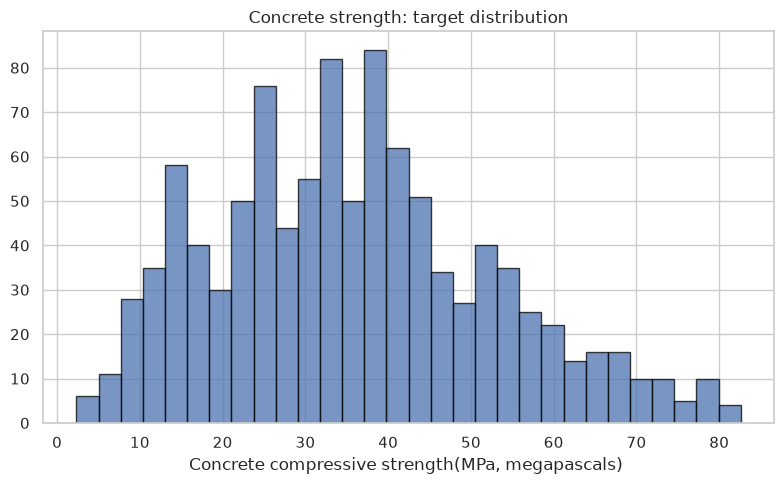

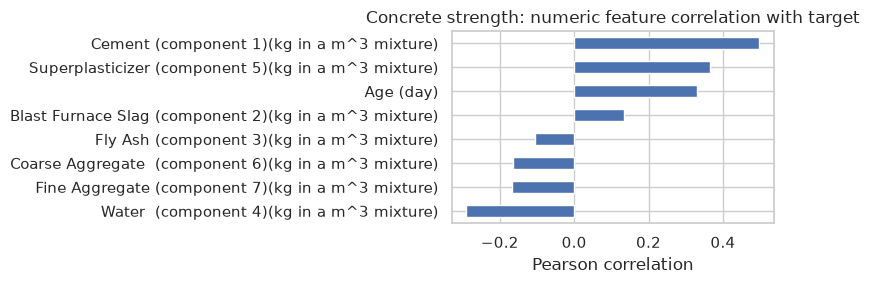


Medical insurance charges | target: charges


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


Target summary:


,count,mean,std,min,25%,50%,75%,max
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


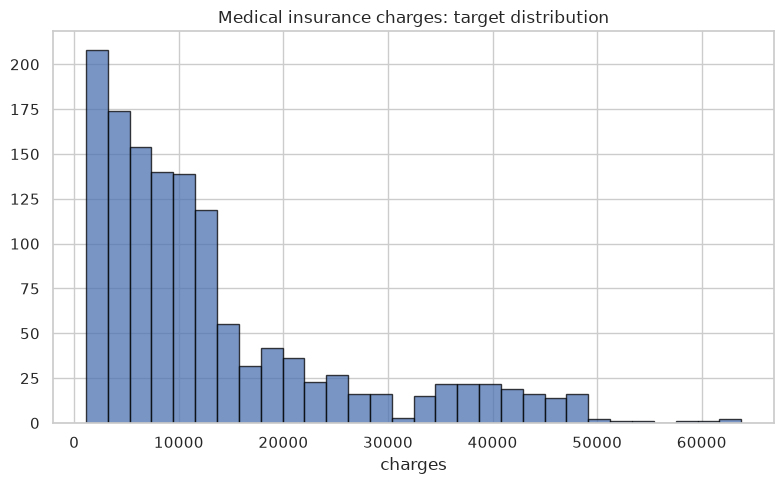

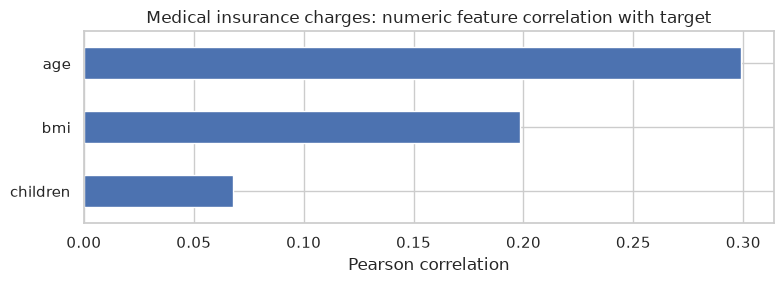


Steel industry energy usage | target: Usage_kWh


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Lagging_Current_Reactive.Power_kVarh,35040.0,NaN,NaN,NaN,13.035384,16.306,0.0,2.3,5.0,22.64,96.91
Leading_Current_Reactive_Power_kVarh,35040.0,NaN,NaN,NaN,3.870949,7.424463,0.0,0.0,0.0,2.09,27.76
Lagging_Current_Power_Factor,35040.0,NaN,NaN,NaN,80.578056,18.921322,0.0,63.32,87.96,99.0225,100.0
Leading_Current_Power_Factor,35040.0,NaN,NaN,NaN,84.36787,30.456535,0.0,99.7,100.0,100.0,100.0
NSM,35040.0,NaN,NaN,NaN,42750.0,24940.534317,0.0,21375.0,42750.0,64125.0,85500.0
WeekStatus,35040,2,Weekday,25056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day_of_week,35040,7,Monday,5088,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Load_Type,35040,3,Light_Load,18072,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hour,35040.0,NaN,NaN,NaN,11.5,6.922285,0.0,5.75,11.5,17.25,23.0
month,35040.0,NaN,NaN,NaN,6.526027,3.447901,1.0,4.0,7.0,10.0,12.0


Target summary:


,count,mean,std,min,25%,50%,75%,max
Usage_kWh,35040.0,27.386892,33.44438,0.0,3.2,4.57,51.2375,157.18


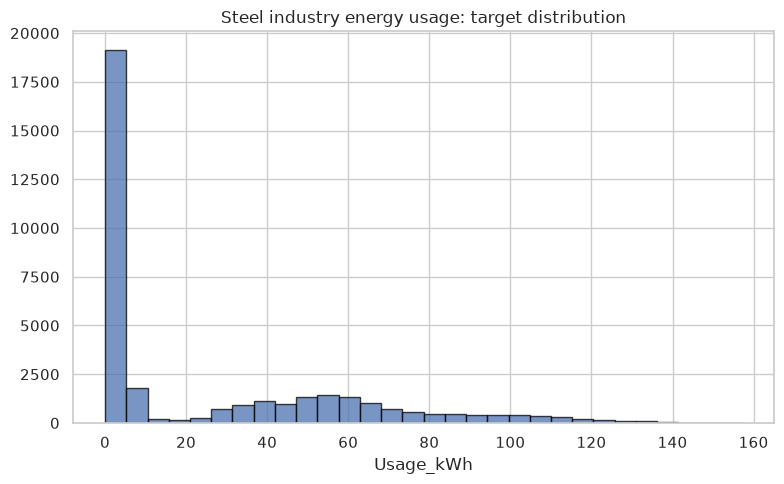

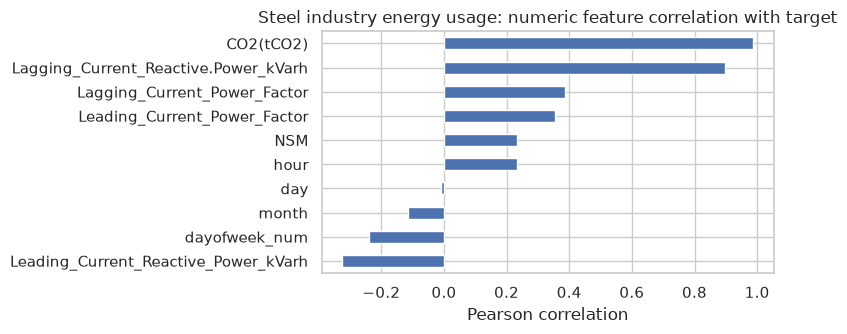

In [4]:
for task in tasks:
    df, target = task["df"], task["target"]
    print("\n" + "=" * 90)
    print(task["name"], "| target:", target)
    display(df[task["features"] + [target]].describe(include="all").T.head(20))
    print("Target summary:")
    display(df[target].describe().to_frame().T)
    fig, ax = plt.subplots()
    ax.hist(pd.to_numeric(df[target], errors="coerce").dropna(), bins=30, edgecolor="black", alpha=0.75)
    ax.set_title(f"{task['name']}: target distribution")
    ax.set_xlabel(target)
    plt.tight_layout()
    plt.show()

    numeric_df = df.select_dtypes(include=np.number)
    if target in numeric_df.columns and numeric_df.shape[1] > 1:
        corr = numeric_df.corr(numeric_only=True)[target].drop(target).sort_values()
        corr = pd.concat([corr.head(5), corr.tail(5)]).drop_duplicates()
        fig, ax = plt.subplots(figsize=(8, max(3, len(corr) * 0.35)))
        corr.sort_values().plot(kind="barh", ax=ax)
        ax.set_title(f"{task['name']}: numeric feature correlation with target")
        ax.set_xlabel("Pearson correlation")
        plt.tight_layout()
        plt.show()

## 5. Regression methods

- **Simple Linear Regression:** uses one numeric predictor.
- **Multiple Linear Regression:** uses all selected predictors.
- **Polynomial Regression (degree 2):** uses one numeric predictor and its squared term.
- **Ridge Regression (L2):** shrinks coefficients to help control overfitting.
- **Lasso Regression (L1):** shrinks coefficients and can set some to zero.

For Simple and Polynomial Regression, the single numeric predictor is selected using training data only. The other methods use all selected predictors, so predictor setups differ. Numeric features are median-imputed and scaled; categorical features are imputed and one-hot encoded. Preprocessing is fitted inside each pipeline to avoid learning from test data.

In [5]:
def make_preprocessor(X):
    # Impute and scale numeric columns; impute and one-hot encode categories.
    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = [c for c in X.columns if c not in numeric_features]

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features)
    ], remainder="drop")


def strongest_numeric_feature(X_train, y_train):
    # Select the numeric predictor with strongest absolute correlation on training data.
    numeric = X_train.select_dtypes(include=np.number)
    if numeric.shape[1] == 0:
        raise ValueError("Simple and Polynomial Regression require a numeric predictor.")
    correlations = numeric.apply(
        lambda col: pd.to_numeric(col, errors="coerce").corr(y_train)
    ).abs().dropna()
    return correlations.idxmax() if not correlations.empty else numeric.columns[0]


def regression_model_specs():
    return [
        "Simple Linear Regression",
        "Multiple Linear Regression",
        "Polynomial Regression (degree 2)",
        "Ridge Regression",
        "Lasso Regression"
    ]

## 6. Train, tune, and evaluate the models

All five methods use the same test observations within each dataset. Concrete and Insurance use a reproducible random 80/20 split. Steel uses the earliest 80% for training and the latest 20% for testing.

Ridge and Lasso alpha values are selected by cross-validation on the training data only. Steel uses time-series cross-validation; the other datasets use shuffled K-fold cross-validation. The test set is not used for tuning.

In [6]:
results = []
fitted_models = {}
predictions = {}
splits = {}
selected_features = {}
best_alpha = {}

alpha_grid = {"model__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}

for task in tasks:
    name, df, target = task["name"], task["df"], task["target"]
    X_all = df[task["features"]].copy()
    y_all = pd.to_numeric(df[target], errors="coerce")
    valid = y_all.notna()
    X_all = X_all.loc[valid].reset_index(drop=True)
    y_all = y_all.loc[valid].reset_index(drop=True)

    if task["time_ordered"]:
        split_idx = int(len(X_all) * 0.8)
        X_train_all, X_test_all = X_all.iloc[:split_idx], X_all.iloc[split_idx:]
        y_train, y_test = y_all.iloc[:split_idx], y_all.iloc[split_idx:]
        cv = TimeSeriesSplit(n_splits=3)
    else:
        X_train_all, X_test_all, y_train, y_test = train_test_split(
            X_all, y_all, test_size=0.2, random_state=RANDOM_STATE
        )
        cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    X_train_all, X_test_all = X_train_all.copy(), X_test_all.copy()
    splits[name] = (X_train_all, X_test_all, y_train, y_test)
    best_feature = strongest_numeric_feature(X_train_all, y_train)
    selected_features[name] = best_feature
    fitted_models[name] = {}
    predictions[name] = {}
    best_alpha[name] = {}

    for model_name in regression_model_specs():
        if model_name in ("Simple Linear Regression", "Polynomial Regression (degree 2)"):
            X_train = X_train_all[[best_feature]].copy()
            X_test = X_test_all[[best_feature]].copy()
            if model_name == "Simple Linear Regression":
                preprocessor = make_preprocessor(X_train)
            else:
                preprocessor = Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("polynomial", PolynomialFeatures(degree=2, include_bias=False))
                ])
            estimator = LinearRegression()
        else:
            X_train, X_test = X_train_all, X_test_all
            preprocessor = make_preprocessor(X_train)
            if model_name == "Multiple Linear Regression":
                estimator = LinearRegression()
            elif model_name == "Ridge Regression":
                estimator = Ridge()
            else:
                estimator = Lasso(max_iter=20000)

        pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])

        if model_name in ("Ridge Regression", "Lasso Regression"):
            search = GridSearchCV(
                pipe,
                param_grid=alpha_grid,
                scoring="neg_root_mean_squared_error",
                cv=cv,
                n_jobs=-1,
                refit=True
            )
            search.fit(X_train, y_train)
            fitted_pipe = search.best_estimator_
            alpha = float(search.best_params_["model__alpha"])
            best_alpha[name][model_name] = alpha
        else:
            fitted_pipe = pipe.fit(X_train, y_train)
            alpha = np.nan

        y_pred = np.asarray(fitted_pipe.predict(X_test))
        mse = mean_squared_error(y_test, y_pred)
        results.append({
            "Dataset": name,
            "Model": model_name,
            "MAE": mean_absolute_error(y_test, y_pred),
            "MSE": mse,
            "RMSE": float(np.sqrt(mse)),
            "R²": r2_score(y_test, y_pred),
            "Predictor setup": (
                f"Single feature: {best_feature}"
                if model_name in ("Simple Linear Regression", "Polynomial Regression (degree 2)")
                else "All selected features"
            ),
            "Best alpha": alpha,
            "Train rows": len(X_train),
            "Test rows": len(X_test)
        })
        fitted_models[name][model_name] = fitted_pipe
        predictions[name][model_name] = (y_test, y_pred)

results_df = pd.DataFrame(results).sort_values(["Dataset", "RMSE"]).reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv(OUTPUT_DIR / "regression_model_metrics.csv", index=False)
print("Saved:", (OUTPUT_DIR / "regression_model_metrics.csv").resolve())

,Dataset,Model,MAE,MSE,RMSE,R²,Predictor setup,Best alpha,Train rows,Test rows
0,Concrete strength,Ridge Regression,7.7462,9.596970e+01,9.7964,0.6276,All selected features,0.100,824,206
1,Concrete strength,Lasso Regression,7.7462,9.597010e+01,9.7964,0.6276,All selected features,0.001,824,206
2,Concrete strength,Multiple Linear Regression,7.7456,9.597090e+01,9.7965,0.6276,All selected features,NaN,824,206
3,Concrete strength,Simple Linear Regression,11.5556,1.927848e+02,13.8847,0.2518,Single feature: Cement (component 1)(kg in a m...,NaN,824,206
4,Concrete strength,Polynomial Regression (degree 2),11.5725,1.931449e+02,13.8977,0.2504,Single feature: Cement (component 1)(kg in a m...,NaN,824,206
5,Medical insurance charges,Multiple Linear Regression,4181.1945,3.359692e+07,5796.2847,0.7836,All selected features,NaN,1070,268
6,Medical insurance charges,Ridge Regression,4181.7628,3.359919e+07,5796.4806,0.7836,All selected features,0.100,1070,268
7,Medical insurance charges,Lasso Regression,4189.3943,3.368343e+07,5803.7429,0.7830,All selected features,10.000,1070,268
8,Medical insurance charges,Simple Linear Regression,9173.2582,1.359840e+08,11661.2160,0.1241,Single feature: age,NaN,1070,268
9,Medical insurance charges,Polynomial Regression (degree 2),9189.4779,1.368150e+08,11696.7946,0.1187,Single feature: age,NaN,1070,268


Saved: /home/shriswarup/Documents/vjti/practicals/ialm/lab-two/outputs/regression_model_metrics.csv


## 7. Compare models with metric charts

Lower MAE, MSE, and RMSE indicate smaller prediction errors. Higher R² indicates that the model explains more variation in the target; test-set R² can be negative. Metric scales differ across datasets, so compare models within each dataset. Numeric labels make values easier to read.

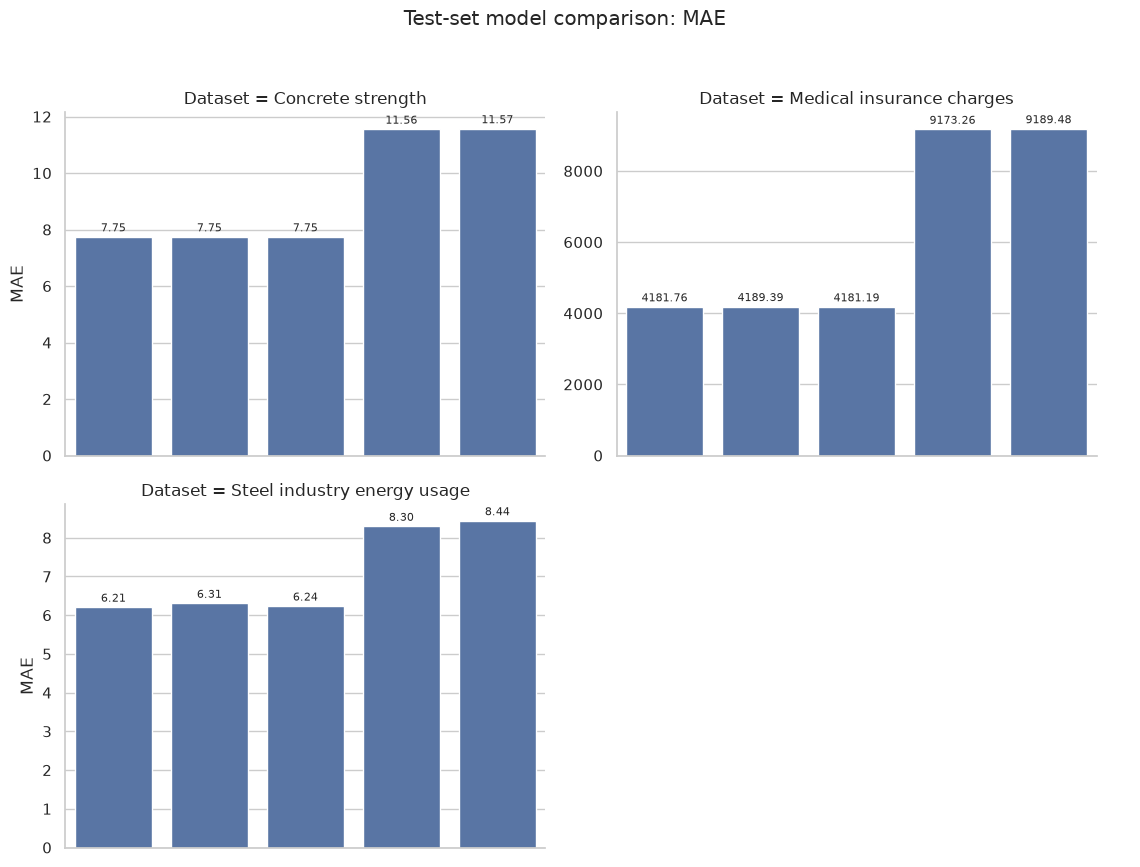

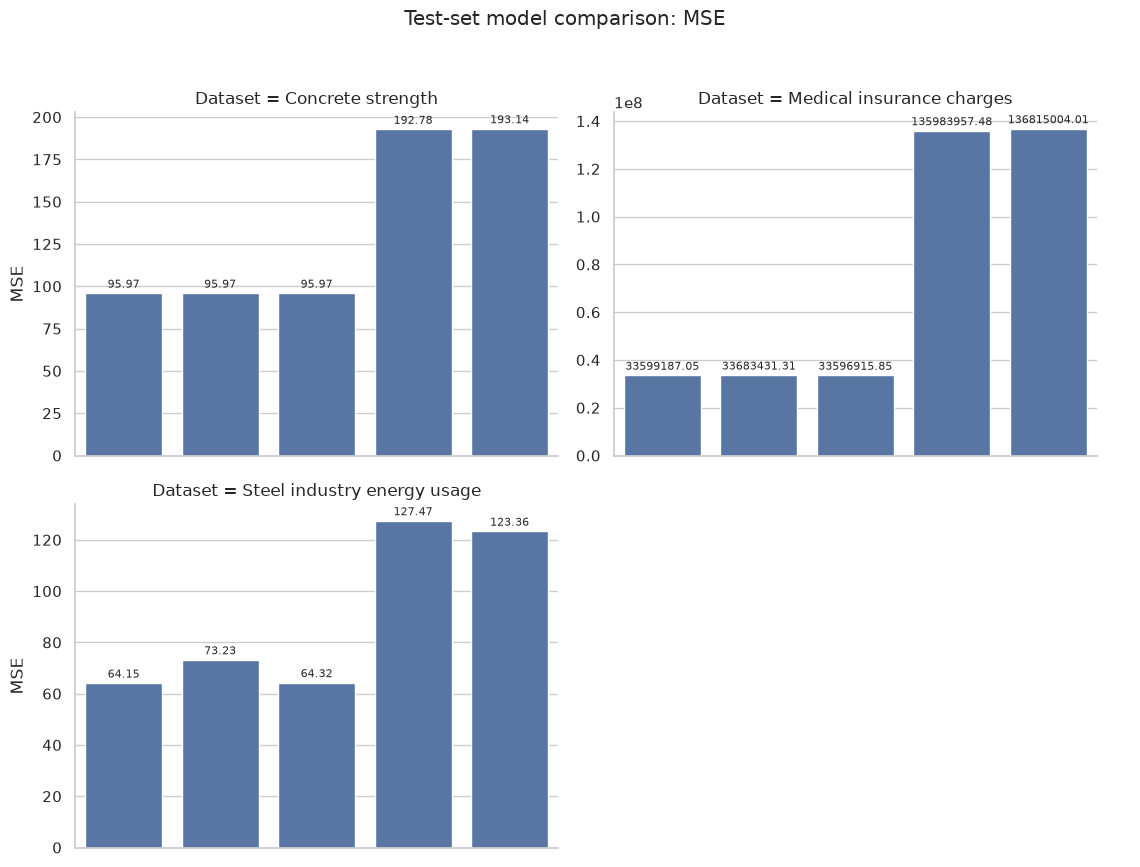

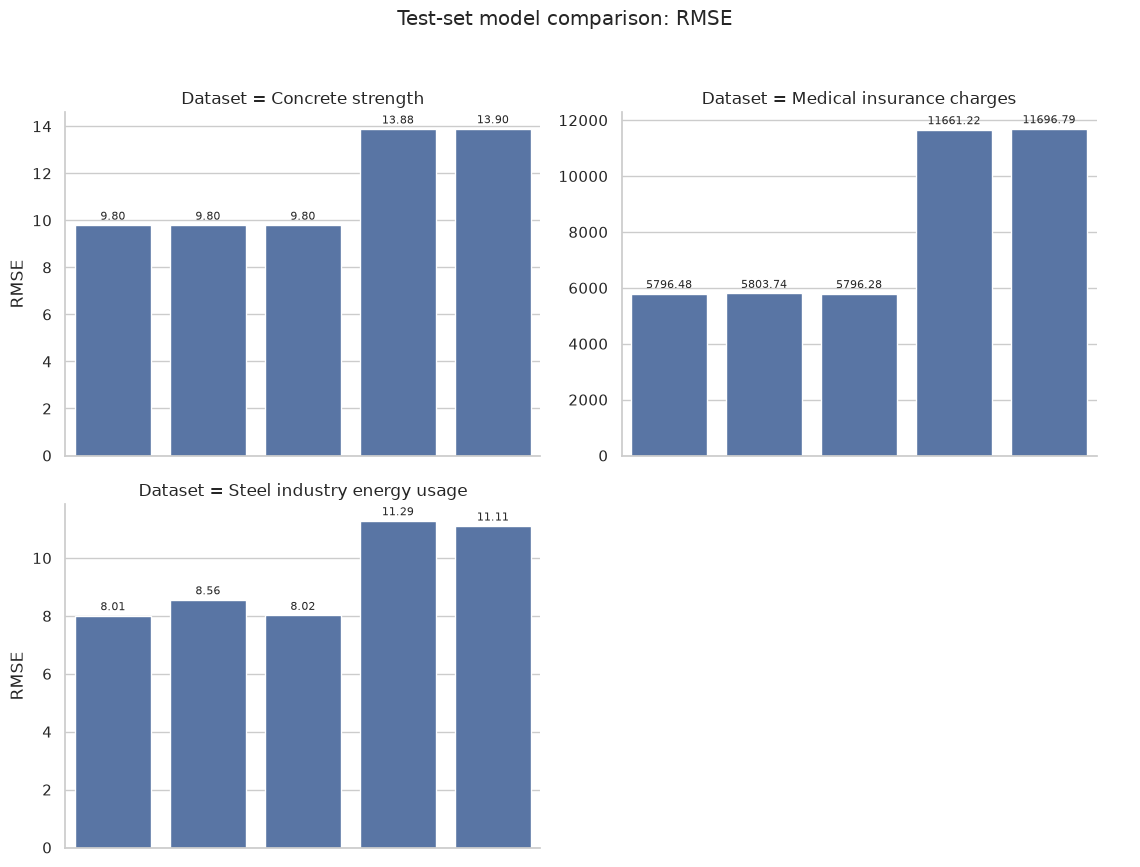

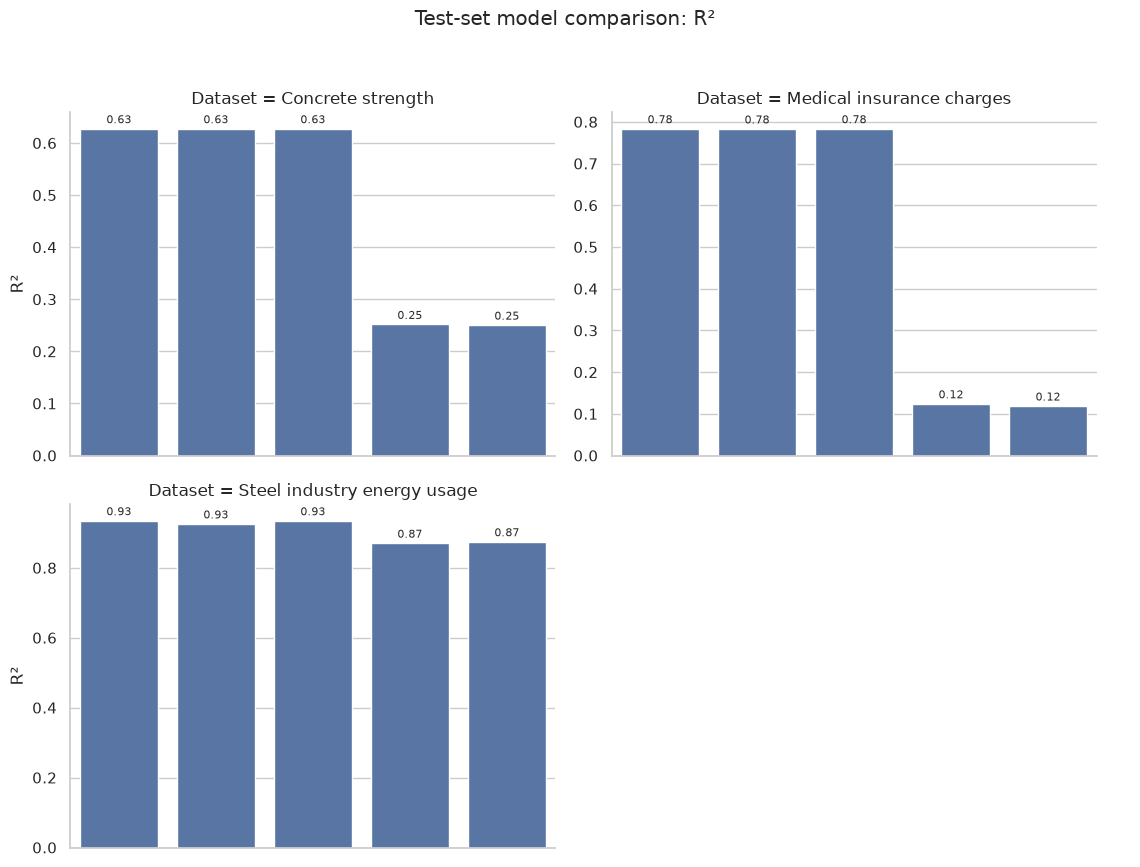

In [7]:
metric_order = ["MAE", "MSE", "RMSE", "R²"]
for metric in metric_order:
    g = sns.catplot(
        data=results_df, x="Model", y=metric, col="Dataset",
        kind="bar", col_wrap=2, sharey=False, height=4.2, aspect=1.35
    )
    g.set_xticklabels(rotation=30, ha="right")
    g.set_axis_labels("", metric)
    g.fig.suptitle(f"Test-set model comparison: {metric}", y=1.03)
    for ax in g.axes.flat:
        for container in ax.containers:
            try:
                ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)
            except (AttributeError, TypeError):
                pass
    g.tight_layout()
    plt.show()

## 8. Actual versus predicted and residual plots

The diagonal represents perfect predictions. Residuals are `actual − predicted`; a useful model should generally have residuals centered near zero without a strong pattern. These plots are diagnostic aids, not proof that all model assumptions are satisfied.

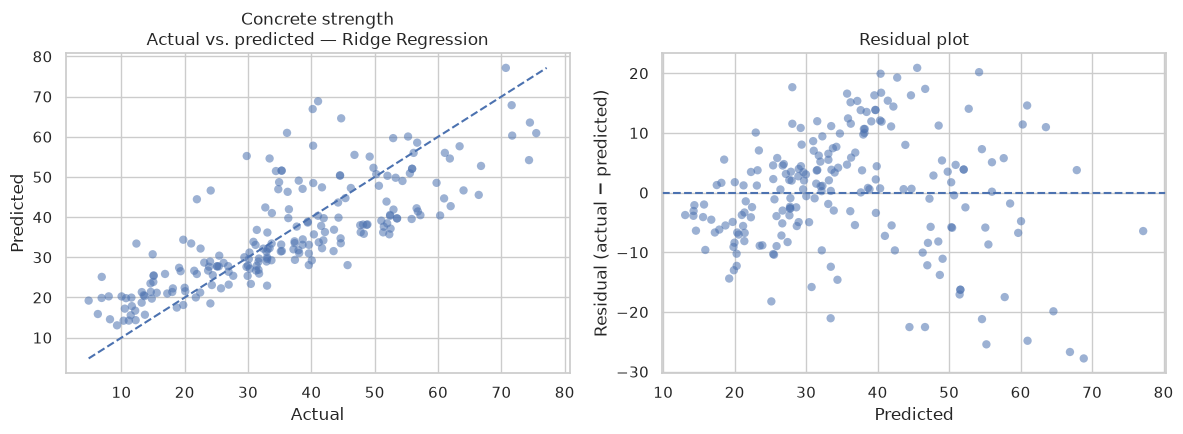

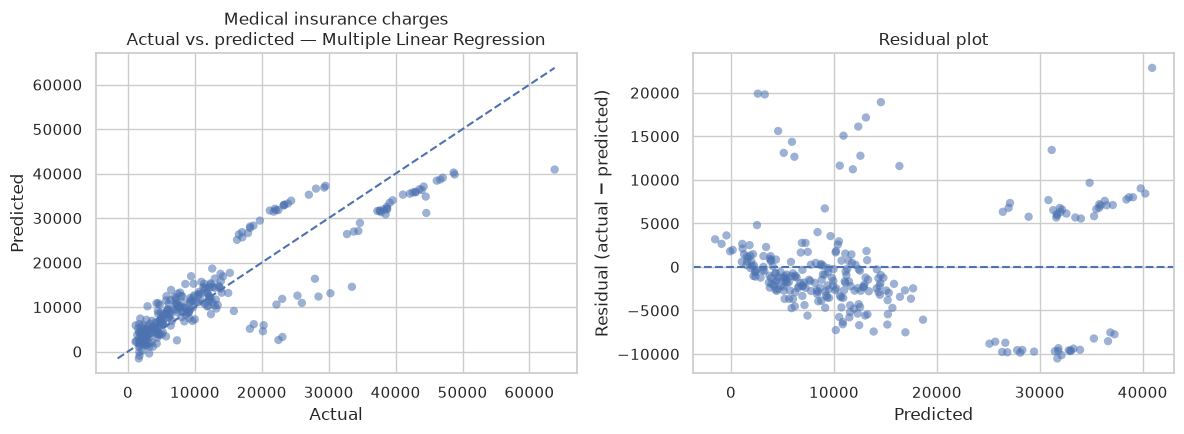

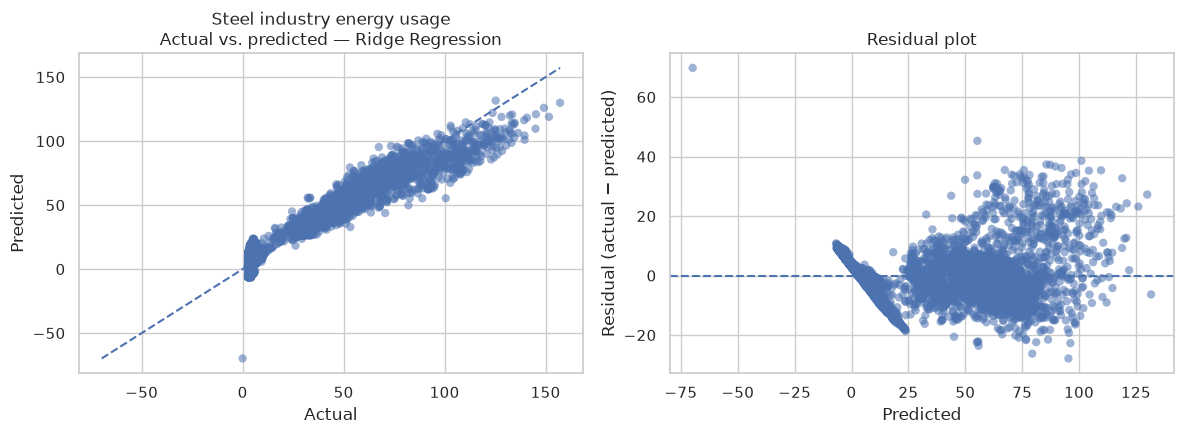

In [8]:
for task in tasks:
    name = task["name"]
    # Plot the best model by test RMSE, then compare residual behavior.
    subset = results_df[results_df["Dataset"] == name]
    best_model_name = subset.sort_values("RMSE").iloc[0]["Model"]
    y_test, y_pred = predictions[name][best_model_name]
    residuals = np.asarray(y_test) - np.asarray(y_pred)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].scatter(y_test, y_pred, alpha=0.55, edgecolor="none")
    lo = min(float(np.min(y_test)), float(np.min(y_pred)))
    hi = max(float(np.max(y_test)), float(np.max(y_pred)))
    axes[0].plot([lo, hi], [lo, hi], linestyle="--")
    axes[0].set_xlabel("Actual")
    axes[0].set_ylabel("Predicted")
    axes[0].set_title(f"{name}\nActual vs. predicted — {best_model_name}")

    axes[1].scatter(y_pred, residuals, alpha=0.55, edgecolor="none")
    axes[1].axhline(0, linestyle="--")
    axes[1].set_xlabel("Predicted")
    axes[1].set_ylabel("Residual (actual − predicted)")
    axes[1].set_title("Residual plot")
    plt.tight_layout()
    plt.show()

### 9. Visualize a feature-target relationship
A regression plot illustrates the relationship between the strongest numeric predictor and the target. This is a univariate visual aid, not the full multivariable model.

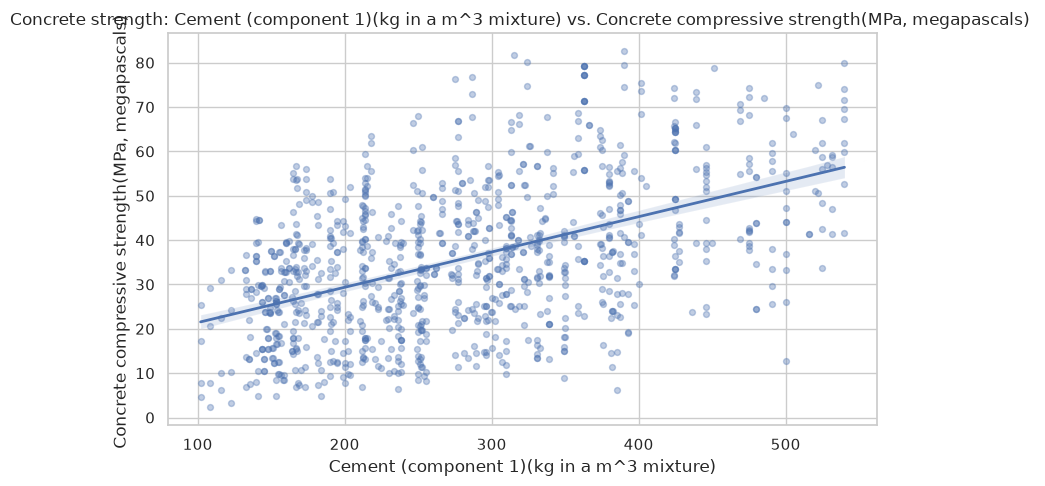

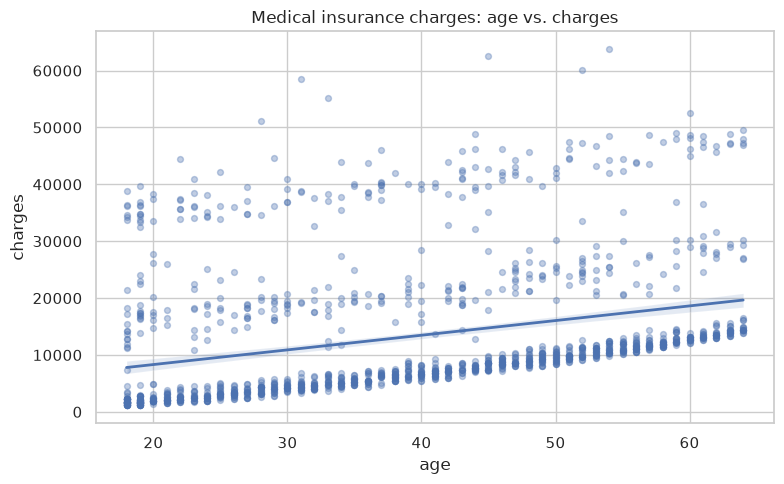

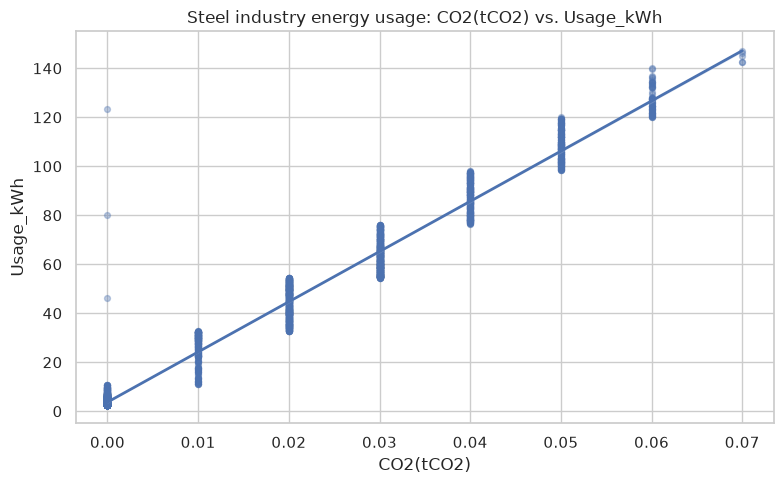

In [9]:
for task in tasks:
    df, target, name = task["df"], task["target"], task["name"]
    numeric = df.select_dtypes(include=np.number)
    candidates = [c for c in numeric.columns if c != target]
    if not candidates:
        print(f"No numeric predictor available for {name}; skipping regression plot.")
        continue
    corr = numeric[candidates + [target]].corr(numeric_only=True)[target].drop(target).abs()
    feature = corr.idxmax()
    plot_df = df[[feature, target]].apply(pd.to_numeric, errors="coerce").dropna()
    # Avoid overplotting for large datasets.
    if len(plot_df) > 5000:
        plot_df = plot_df.sample(5000, random_state=RANDOM_STATE)
    fig, ax = plt.subplots()
    sns.regplot(data=plot_df, x=feature, y=target,
                scatter_kws={"alpha": 0.35, "s": 18},
                line_kws={"linewidth": 2}, ax=ax)
    ax.set_title(f"{name}: {feature} vs. {target}")
    plt.tight_layout()
    plt.show()

## 10. Best model per dataset

For a descriptive summary, the model with the lowest **test-set RMSE** is displayed for each dataset. Since the same test scores are used to identify and report the winner, this selection can be optimistic. Treat it as a comparison on this holdout split, not a definitive estimate of future performance.

In [10]:
best_rows = (
    results_df.sort_values("RMSE")
    .groupby("Dataset", as_index=False)
    .first()
    .sort_values("Dataset")
)
display(best_rows[["Dataset", "Model", "MAE", "MSE", "RMSE", "R²", "Predictor setup", "Best alpha"]].round(4))
best_rows.to_csv(OUTPUT_DIR / "best_model_per_dataset.csv", index=False)
print("Saved:", (OUTPUT_DIR / "best_model_per_dataset.csv").resolve())

for _, row in best_rows.iterrows():
    print(
        f"{row['Dataset']}: lowest test RMSE = {row['Model']} "
        f"(MAE={row['MAE']:.3f}, RMSE={row['RMSE']:.3f}, R²={row['R²']:.3f})."
    )

,Dataset,Model,MAE,MSE,RMSE,R²,Predictor setup,Best alpha
0,Concrete strength,Ridge Regression,7.7462,9.596970e+01,9.7964,0.6276,All selected features,0.1
1,Medical insurance charges,Multiple Linear Regression,4181.1945,3.359692e+07,5796.2847,0.7836,All selected features,0.1
2,Steel industry energy usage,Ridge Regression,6.2078,6.414890e+01,8.0093,0.9348,All selected features,100.0


Saved: /home/shriswarup/Documents/vjti/practicals/ialm/lab-two/outputs/best_model_per_dataset.csv
Concrete strength: lowest test RMSE = Ridge Regression (MAE=7.746, RMSE=9.796, R²=0.628).
Medical insurance charges: lowest test RMSE = Multiple Linear Regression (MAE=4181.194, RMSE=5796.285, R²=0.784).
Steel industry energy usage: lowest test RMSE = Ridge Regression (MAE=6.208, RMSE=8.009, R²=0.935).


## 11. Inspect residual distributions

Residual histograms help identify skew, long tails, or systematic over/under-prediction. Interpret them alongside the residual scatter plots and numerical metrics.

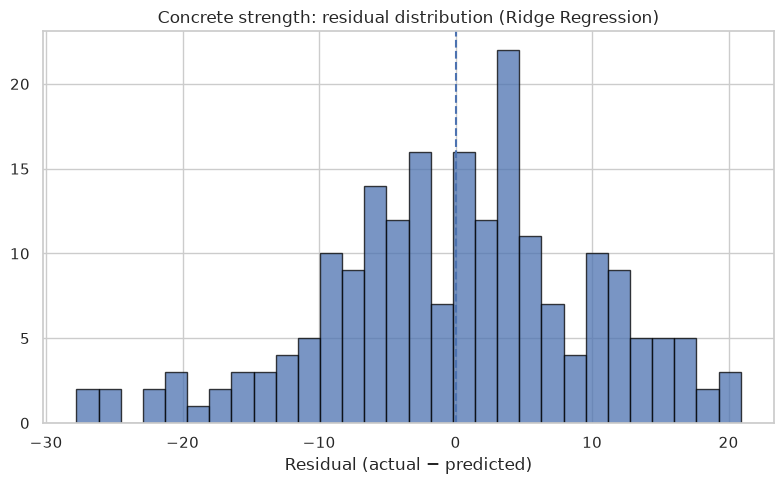

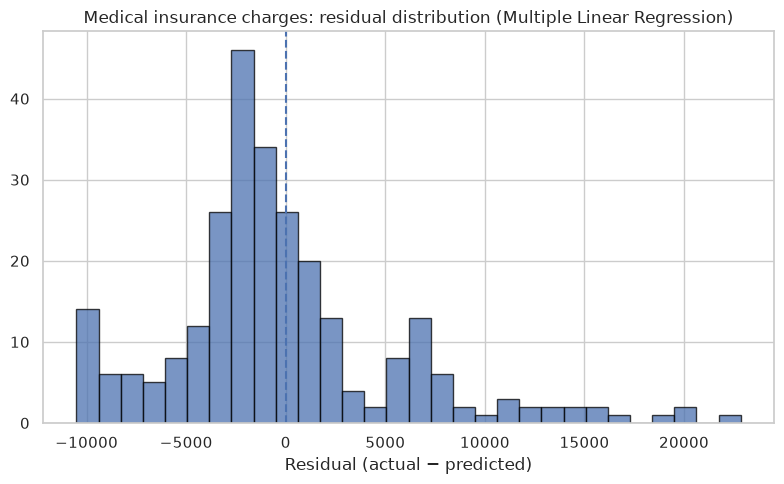

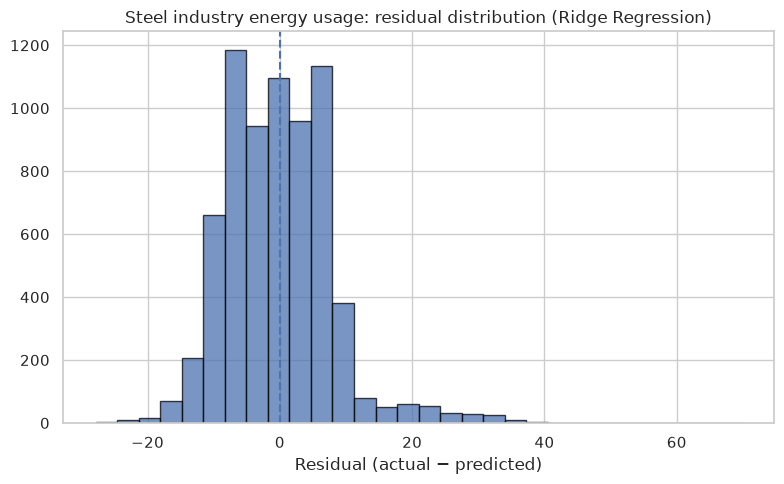

In [11]:
for task in tasks:
    name = task["name"]
    best_model_name = best_rows.loc[best_rows["Dataset"] == name, "Model"].iloc[0]
    y_test, y_pred = predictions[name][best_model_name]
    residuals = np.asarray(y_test) - np.asarray(y_pred)
    fig, ax = plt.subplots()
    ax.hist(residuals, bins=30, edgecolor="black", alpha=0.75)
    ax.axvline(0, linestyle="--")
    ax.set_title(f"{name}: residual distribution ({best_model_name})")
    ax.set_xlabel("Residual (actual − predicted)")
    plt.tight_layout()
    plt.show()

### Regression Explorer

Deployed at : https://shri-regression-explorer.streamlit.app/

Repository : https://github.com/iamshrisawant/ialm